In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Definisi direktori file
build_dir = r"E:\Tugas Akhir\New Firmware\build"
data_dir  = r"E:\Tugas Akhir\New Firmware\Sim\data"

# Muat dataset hasil fusi EKF, referensi GNSS, dan INS murni (Pure INS)
df_ekf = pd.read_csv(os.path.join(build_dir, 'ins_ekf_fused_trajectory.csv'))
df_gps = pd.read_csv(os.path.join(data_dir, 'Dataset_vehicle_gps_position_0.csv'))
df_ins = pd.read_excel(os.path.join(data_dir, 'Dataset_INS_GNSS_Analysis.xlsx'), sheet_name='INS_Estimated_Trajectory')

# Seragamkan sumbu waktu ke detik relatif mulai dari awal simulasi (t0)
t0 = df_ekf['timestamp'].iloc[0]
df_ekf['t_sec'] = df_ekf['timestamp'] - t0
df_ins['t_sec'] = df_ins['timestamp'] - t0
df_gps['t_sec'] = (df_gps['timestamp'] * 1e-6) - t0

print(f"Durasi penerbangan : {df_ekf['t_sec'].max():.2f} detik")
print(f"Jumlah data EKF    : {len(df_ekf)} baris")
print(f"Jumlah data GNSS   : {len(df_gps)} baris")

Durasi penerbangan : 128.77 detik
Jumlah data EKF    : 21233 baris
Jumlah data GNSS   : 1031 baris


In [6]:
# Titik referensi awal penerbangan (Datum Home)
lat0 = np.radians(df_gps['latitude_deg'].iloc[0])
lon0 = np.radians(df_gps['longitude_deg'].iloc[0])
h0   = df_gps['altitude_ellipsoid_m'].iloc[0]

# Konstanta Elipsoid WGS-84
R0     = 6378137.0
E_SQR  = 0.00669437999014
sin_L0 = np.sin(lat0)
RN = R0 * (1.0 - E_SQR) / ((1.0 - E_SQR * sin_L0**2)**1.5)
RE = R0 / np.sqrt(1.0 - E_SQR * sin_L0**2)

def geodetic_to_ned(lat_deg, lon_deg):
    north_m = (np.radians(lat_deg) - lat0) * (RN + h0)
    east_m  = (np.radians(lon_deg) - lon0) * (RE + h0) * np.cos(lat0)
    return north_m, east_m

df_gps['North_m'], df_gps['East_m'] = geodetic_to_ned(df_gps['latitude_deg'], df_gps['longitude_deg'])
df_ekf['North_m'], df_ekf['East_m'] = geodetic_to_ned(df_ekf['latitude_deg'], df_ekf['longitude_deg'])
df_ins['North_m'], df_ins['East_m'] = geodetic_to_ned(df_ins['latitude_deg'], df_ins['longitude_deg'])

In [7]:
# Ambil sampel GNSS yang berada dalam rentang waktu simulasi
mask_valid = (df_gps['t_sec'] >= df_ekf['t_sec'].min()) & (df_gps['t_sec'] <= df_ekf['t_sec'].max())
gps_ref = df_gps[mask_valid].reset_index(drop=True)

def evaluasi_error(df_est, ref):
    t_ref = ref['t_sec'].values
    t_est = df_est['t_sec'].values

    err_n  = np.interp(t_ref, t_est, df_est['North_m'].values) - ref['North_m'].values
    err_e  = np.interp(t_ref, t_est, df_est['East_m'].values) - ref['East_m'].values
    err_2d = np.sqrt(err_n**2 + err_e**2)
    err_h  = np.interp(t_ref, t_est, df_est['height_m'].values) - ref['altitude_ellipsoid_m'].values
    err_vn = np.interp(t_ref, t_est, df_est['v_N'].values) - ref['vel_n_m_s'].values
    err_ve = np.interp(t_ref, t_est, df_est['v_E'].values) - ref['vel_e_m_s'].values
    err_vd = np.interp(t_ref, t_est, df_est['v_D'].values) - ref['vel_d_m_s'].values

    hasil = []
    daftar_variabel = [
        ('Posisi Horizontal 2D (m)', err_2d),
        ('Posisi North (m)', err_n),
        ('Posisi East (m)', err_e),
        ('Ketinggian / Altitude (m)', err_h),
        ('Kecepatan North v_N (m/s)', err_vn),
        ('Kecepatan East v_E (m/s)', err_ve),
        ('Kecepatan Down v_D (m/s)', err_vd),
    ]
    for nama, e in daftar_variabel:
        mae  = np.mean(np.abs(e))
        mse  = np.mean(e**2)
        rmse = np.sqrt(mse)
        maks = np.max(np.abs(e))
        hasil.append({'Parameter': nama, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'Max Error': maks})
    
    seri_error = {
        't': t_ref, 'err_2d': err_2d, 'err_n': err_n, 'err_e': err_e,
        'err_h': err_h, 'err_vn': err_vn, 'err_ve': err_ve, 'err_vd': err_vd
    }
    return pd.DataFrame(hasil), seri_error

df_err_ins, seri_ins = evaluasi_error(df_ins, gps_ref)
df_err_ekf, seri_ekf = evaluasi_error(df_ekf, gps_ref)

tabel_perbandingan = pd.DataFrame({
    'Parameter': df_err_ekf['Parameter'],
    'Pure INS RMSE': df_err_ins['RMSE'],
    'INS+EKF MAE': df_err_ekf['MAE'],
    'INS+EKF MSE': df_err_ekf['MSE'],
    'INS+EKF RMSE': df_err_ekf['RMSE'],
    'INS+EKF Max Error': df_err_ekf['Max Error'],
    'Reduksi Error (%)': (1.0 - df_err_ekf['RMSE'] / df_err_ins['RMSE']) * 100.0
})

display(tabel_perbandingan.round(4))

,Parameter,Pure INS RMSE,INS+EKF MAE,INS+EKF MSE,INS+EKF RMSE,INS+EKF Max Error,Reduksi Error (%)
0,Posisi Horizontal 2D (m),2324.5072,0.1713,0.0393,0.1983,0.3723,99.9915
1,Posisi North (m),1630.9753,0.0653,0.0070,0.0834,0.2207,99.9949
2,Posisi East (m),1656.2769,0.1489,0.0324,0.1799,0.3407,99.9891
3,Ketinggian / Altitude (m),14.2745,0.5979,0.4520,0.6723,1.2154,95.2899
4,Kecepatan North v_N (m/s),39.6192,0.1467,0.0347,0.1862,0.6269,99.5300
5,Kecepatan East v_E (m/s),34.3184,0.3042,0.1488,0.3858,0.9141,98.8759
6,Kecepatan Down v_D (m/s),0.9119,0.0643,0.0066,0.0809,0.4660,91.1246


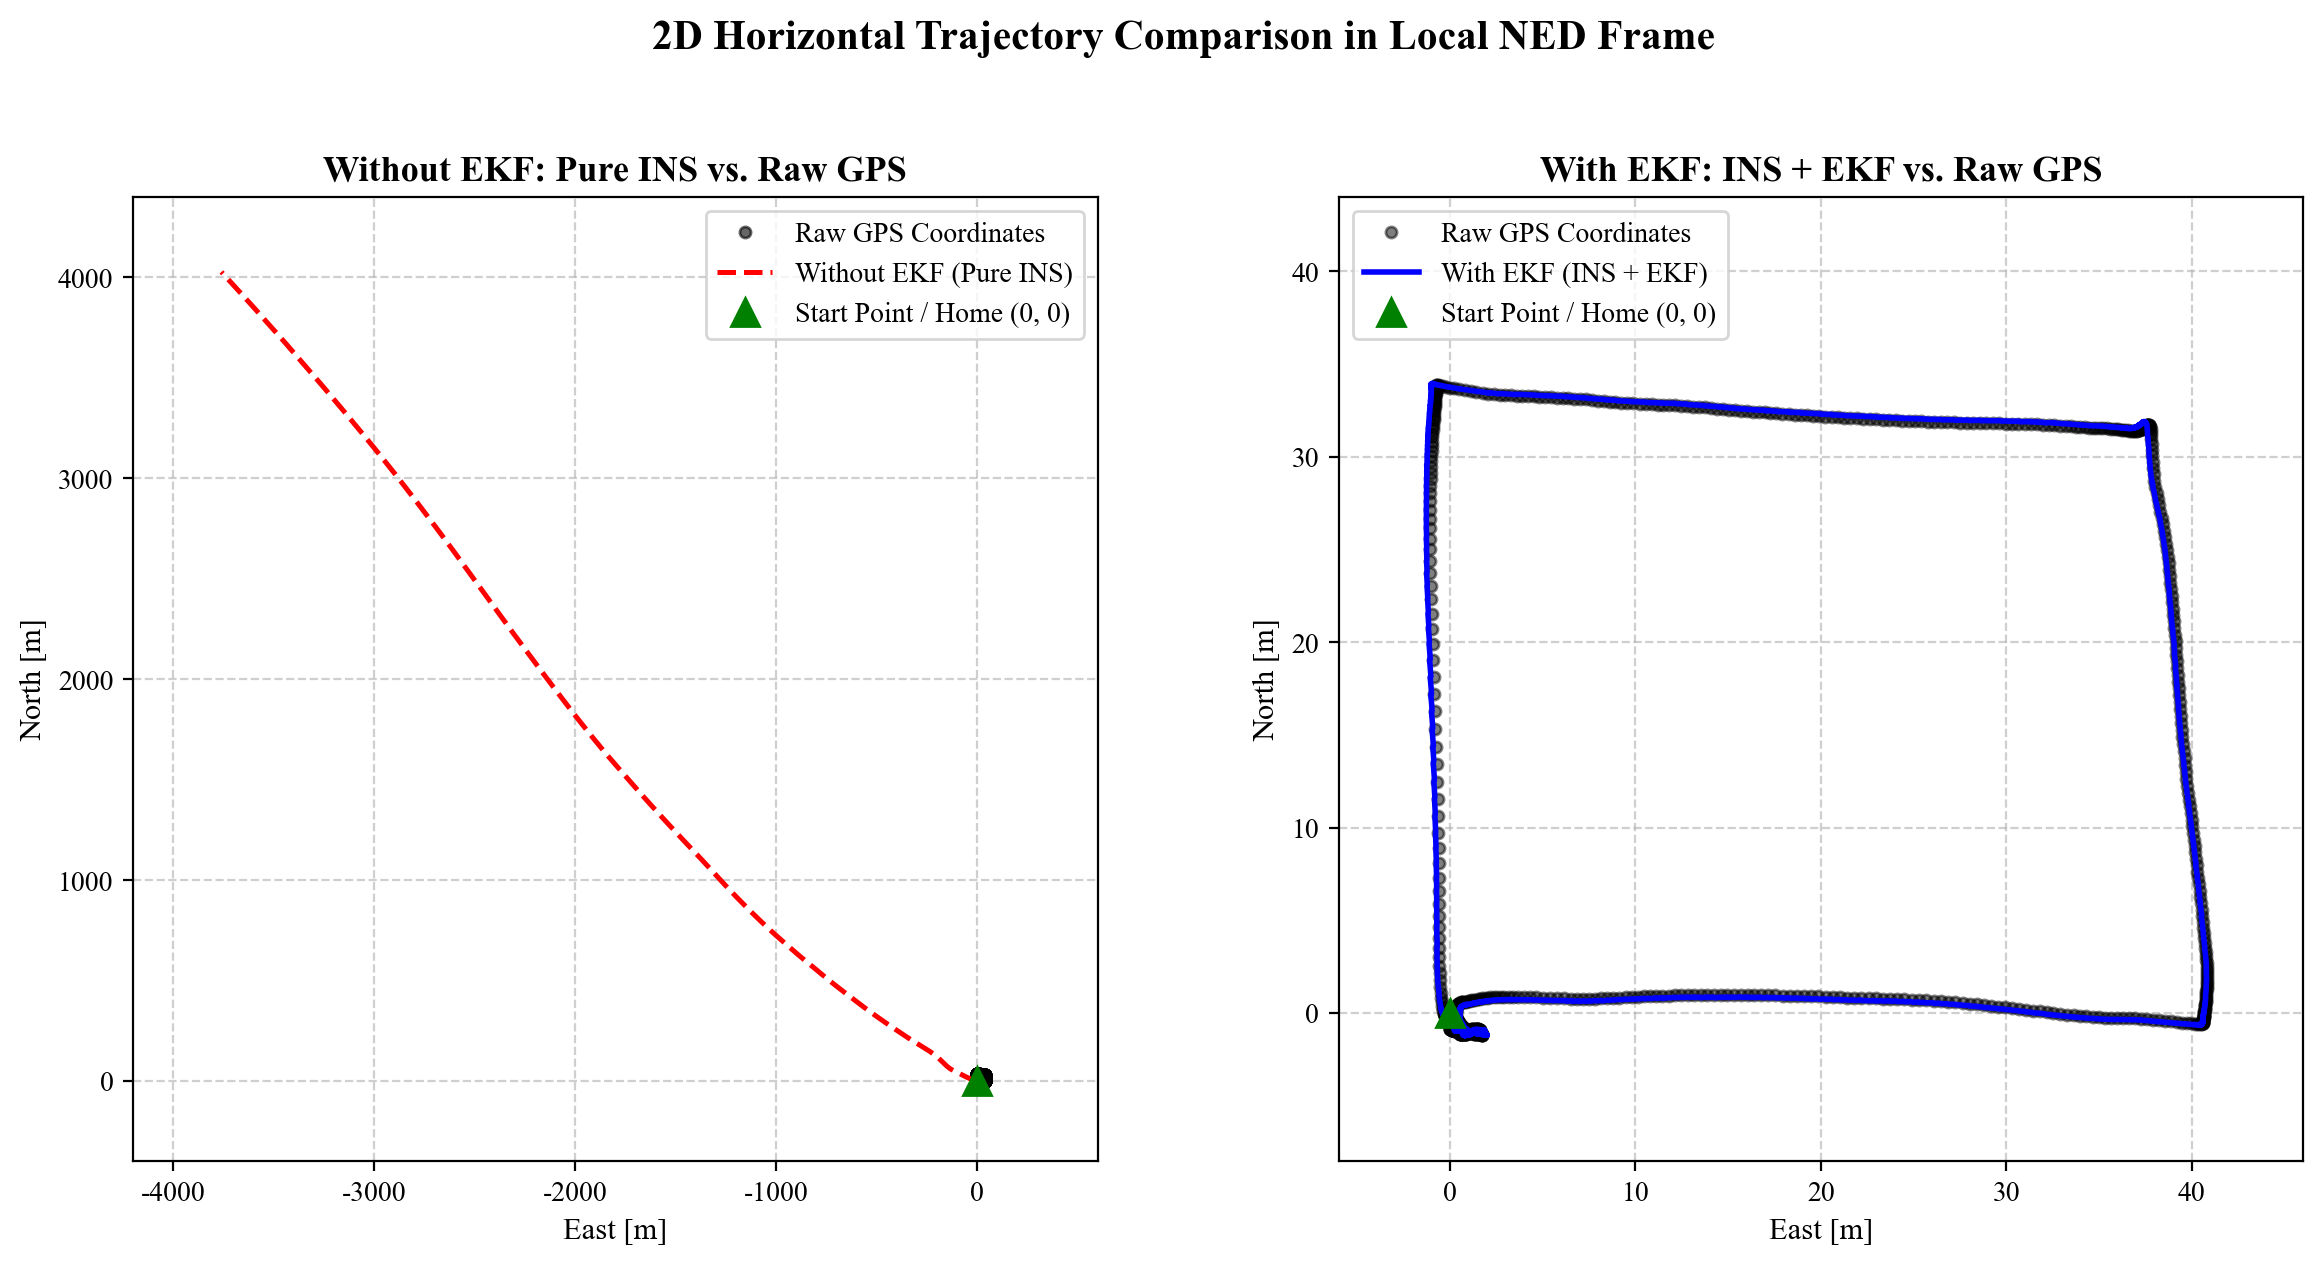

,Axis / Metric,Pure INS RMSE,Pure INS Max Error,INS+EKF MAE,INS+EKF MSE,INS+EKF RMSE,INS+EKF Max Error,RMSE Reduction (%)
0,North Position [m],1630.9753,4018.9217,0.0653,0.0070,0.0834,0.2207,99.9949
1,East Position [m],1656.2769,3752.2096,0.1489,0.0324,0.1799,0.3407,99.9891
2,2D Horizontal Position [m],2324.5072,5498.2550,0.1713,0.0393,0.1983,0.3723,99.9915


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Konfigurasi Global Font Times New Roman
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

# 2. Buat Kanvas 2 Grafik Berdampingan dengan Dimensi Kotak Identik
fig, axes = plt.subplots(1, 2, figsize=(14, 6.8), dpi=200)
plt.subplots_adjust(wspace=0.25)

# --- GRAFIK KIRI: Tanpa EKF (Rentang Persegi 4800 m x 4800 m) ---
axes[0].plot(df_gps['East_m'], df_gps['North_m'], 'ko', markersize=4, alpha=0.6, label='Raw GPS Coordinates')
axes[0].plot(df_ins['East_m'], df_ins['North_m'], 'r--', linewidth=1.8, label='Without EKF (Pure INS)')
axes[0].plot(0, 0, 'g^', markersize=10, zorder=5, label='Start Point / Home (0, 0)')

axes[0].set_xlim(-4200, 600)   # Rentang X = 4800 m
axes[0].set_ylim(-400, 4400)   # Rentang Y = 4800 m
axes[0].set_aspect('equal', adjustable='box')
axes[0].set_title('Without EKF: Pure INS vs. Raw GPS', fontsize=13, fontweight='bold')
axes[0].set_xlabel('East [m]', fontsize=11)
axes[0].set_ylabel('North [m]', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='upper right', fontsize=10)

# --- GRAFIK KANAN: Menggunakan EKF (Rentang Persegi 52 m x 52 m) ---
axes[1].plot(df_gps['East_m'], df_gps['North_m'], 'ko', markersize=4, alpha=0.5, label='Raw GPS Coordinates')
axes[1].plot(df_ekf['East_m'], df_ekf['North_m'], 'b-', linewidth=2.0, label='With EKF (INS + EKF)')
axes[1].plot(0, 0, 'g^', markersize=10, zorder=5, label='Start Point / Home (0, 0)')

axes[1].set_xlim(-6, 46)       # Rentang X = 52 m
axes[1].set_ylim(-8, 44)       # Rentang Y = 52 m
axes[1].set_aspect('equal', adjustable='box')
axes[1].set_title('With EKF: INS + EKF vs. Raw GPS', fontsize=13, fontweight='bold')
axes[1].set_xlabel('East [m]', fontsize=11)
axes[1].set_ylabel('North [m]', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='upper left', fontsize=10)

fig.suptitle('2D Horizontal Trajectory Comparison in Local NED Frame', fontsize=15, fontweight='bold', y=0.98)
plt.savefig('trajectory_2d_equal_size.png', bbox_inches='tight')
plt.show()

# 3. Tabel Metrik Error Posisi Horizontal (Ditampilkan Tepat di Bawah Grafik)
mask_valid = (df_gps['t_sec'] >= df_ekf['t_sec'].min()) & (df_gps['t_sec'] <= df_ekf['t_sec'].max())
gps_ref = df_gps[mask_valid].reset_index(drop=True)
t_ref = gps_ref['t_sec'].values

err_ins_n  = np.interp(t_ref, df_ins['t_sec'].values, df_ins['North_m'].values) - gps_ref['North_m'].values
err_ins_e  = np.interp(t_ref, df_ins['t_sec'].values, df_ins['East_m'].values) - gps_ref['East_m'].values
err_ins_2d = np.sqrt(err_ins_n**2 + err_ins_e**2)

err_ekf_n  = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['North_m'].values) - gps_ref['North_m'].values
err_ekf_e  = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['East_m'].values) - gps_ref['East_m'].values
err_ekf_2d = np.sqrt(err_ekf_n**2 + err_ekf_e**2)

def calc_stats(err):
    mae   = np.mean(np.abs(err))
    mse   = np.mean(err**2)
    rmse  = np.sqrt(mse)
    max_e = np.max(np.abs(err))
    return mae, mse, rmse, max_e

rows = []
for label, e_ins, e_ekf in [
    ('North Position [m]', err_ins_n, err_ekf_n),
    ('East Position [m]', err_ins_e, err_ekf_e),
    ('2D Horizontal Position [m]', err_ins_2d, err_ekf_2d)
]:
    _, _, ins_rmse, ins_max = calc_stats(e_ins)
    ekf_mae, ekf_mse, ekf_rmse, ekf_max = calc_stats(e_ekf)
    rows.append({
        'Axis / Metric': label,
        'Pure INS RMSE': ins_rmse,
        'Pure INS Max Error': ins_max,
        'INS+EKF MAE': ekf_mae,
        'INS+EKF MSE': ekf_mse,
        'INS+EKF RMSE': ekf_rmse,
        'INS+EKF Max Error': ekf_max,
        'RMSE Reduction (%)': (1.0 - ekf_rmse / ins_rmse) * 100.0
    })

df_2d_table = pd.DataFrame(rows)
display(df_2d_table.round(4))

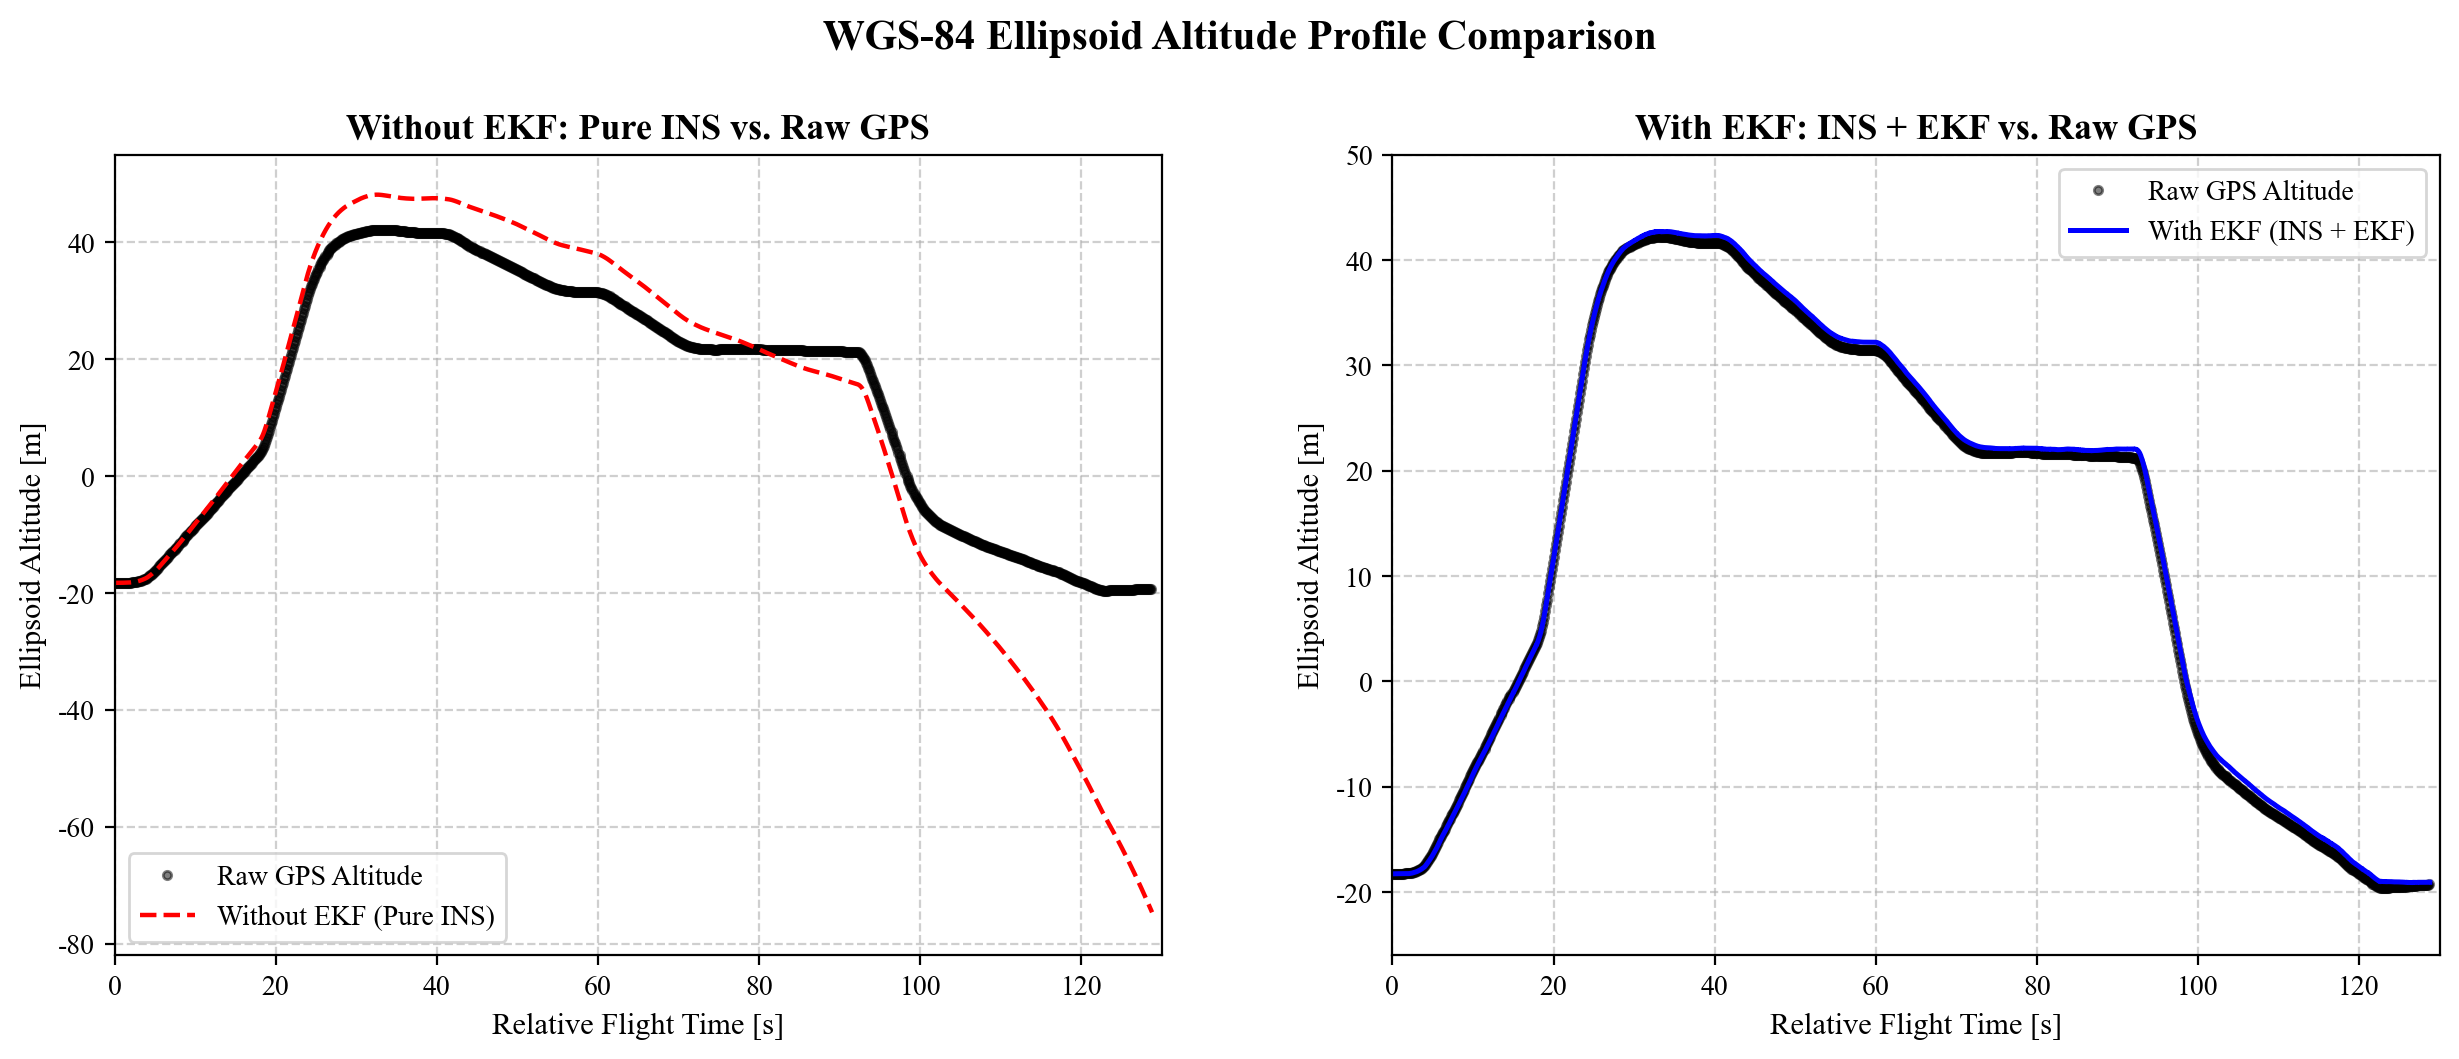

,Axis / Metric,Pure INS RMSE,Pure INS Max Error,INS+EKF MAE,INS+EKF MSE,INS+EKF RMSE,INS+EKF Max Error,RMSE Reduction (%)
0,Ellipsoid Altitude [m],14.2745,55.0073,0.5979,0.452,0.6723,1.2154,95.2899


In [18]:
# 1. Konfigurasi Global Font Times New Roman
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

# 2. Buat Kanvas 2 Grafik Berdampingan dengan Ukuran Identik
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), dpi=200)
plt.subplots_adjust(wspace=0.22)

# --- GRAFIK KIRI: Tanpa EKF (Pure INS vs. Raw GPS Altitude) ---
axes[0].plot(df_gps['t_sec'], df_gps['altitude_ellipsoid_m'], 'ko', markersize=3, alpha=0.5, label='Raw GPS Altitude')
axes[0].plot(df_ins['t_sec'], df_ins['height_m'], 'r--', linewidth=1.6, label='Without EKF (Pure INS)')

axes[0].set_xlim(0, 130)
axes[0].set_ylim(-82, 55)
axes[0].set_title('Without EKF: Pure INS vs. Raw GPS', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Relative Flight Time [s]', fontsize=11)
axes[0].set_ylabel('Ellipsoid Altitude [m]', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='lower left', fontsize=10)

# --- GRAFIK KANAN: Menggunakan EKF (INS + EKF vs. Raw GPS Altitude) ---
axes[1].plot(df_gps['t_sec'], df_gps['altitude_ellipsoid_m'], 'ko', markersize=3, alpha=0.5, label='Raw GPS Altitude')
axes[1].plot(df_ekf['t_sec'], df_ekf['height_m'], 'b-', linewidth=1.8, label='With EKF (INS + EKF)')

axes[1].set_xlim(0, 130)
axes[1].set_ylim(-26, 50)
axes[1].set_title('With EKF: INS + EKF vs. Raw GPS', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Relative Flight Time [s]', fontsize=11)
axes[1].set_ylabel('Ellipsoid Altitude [m]', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='upper right', fontsize=10)

fig.suptitle('WGS-84 Ellipsoid Altitude Profile Comparison', fontsize=15, fontweight='bold', y=1.01)
plt.savefig('altitude_comparison.png', bbox_inches='tight')
plt.show()

# 3. Tabel Metrik Error Ketinggian (Ditampilkan Tepat di Bawah Grafik)
mask_valid = (df_gps['t_sec'] >= df_ekf['t_sec'].min()) & (df_gps['t_sec'] <= df_ekf['t_sec'].max())
gps_ref = df_gps[mask_valid].reset_index(drop=True)
t_ref = gps_ref['t_sec'].values

err_ins_alt = np.interp(t_ref, df_ins['t_sec'].values, df_ins['height_m'].values) - gps_ref['altitude_ellipsoid_m'].values
err_ekf_alt = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['height_m'].values) - gps_ref['altitude_ellipsoid_m'].values

def calc_stats(err):
    mae   = np.mean(np.abs(err))
    mse   = np.mean(err**2)
    rmse  = np.sqrt(mse)
    max_e = np.max(np.abs(err))
    return mae, mse, rmse, max_e

_, _, ins_rmse, ins_max = calc_stats(err_ins_alt)
ekf_mae, ekf_mse, ekf_rmse, ekf_max = calc_stats(err_ekf_alt)

df_alt_table = pd.DataFrame([{
    'Axis / Metric': 'Ellipsoid Altitude [m]',
    'Pure INS RMSE': ins_rmse,
    'Pure INS Max Error': ins_max,
    'INS+EKF MAE': ekf_mae,
    'INS+EKF MSE': ekf_mse,
    'INS+EKF RMSE': ekf_rmse,
    'INS+EKF Max Error': ekf_max,
    'RMSE Reduction (%)': (1.0 - ekf_rmse / ins_rmse) * 100.0
}])

display(df_alt_table.round(4))

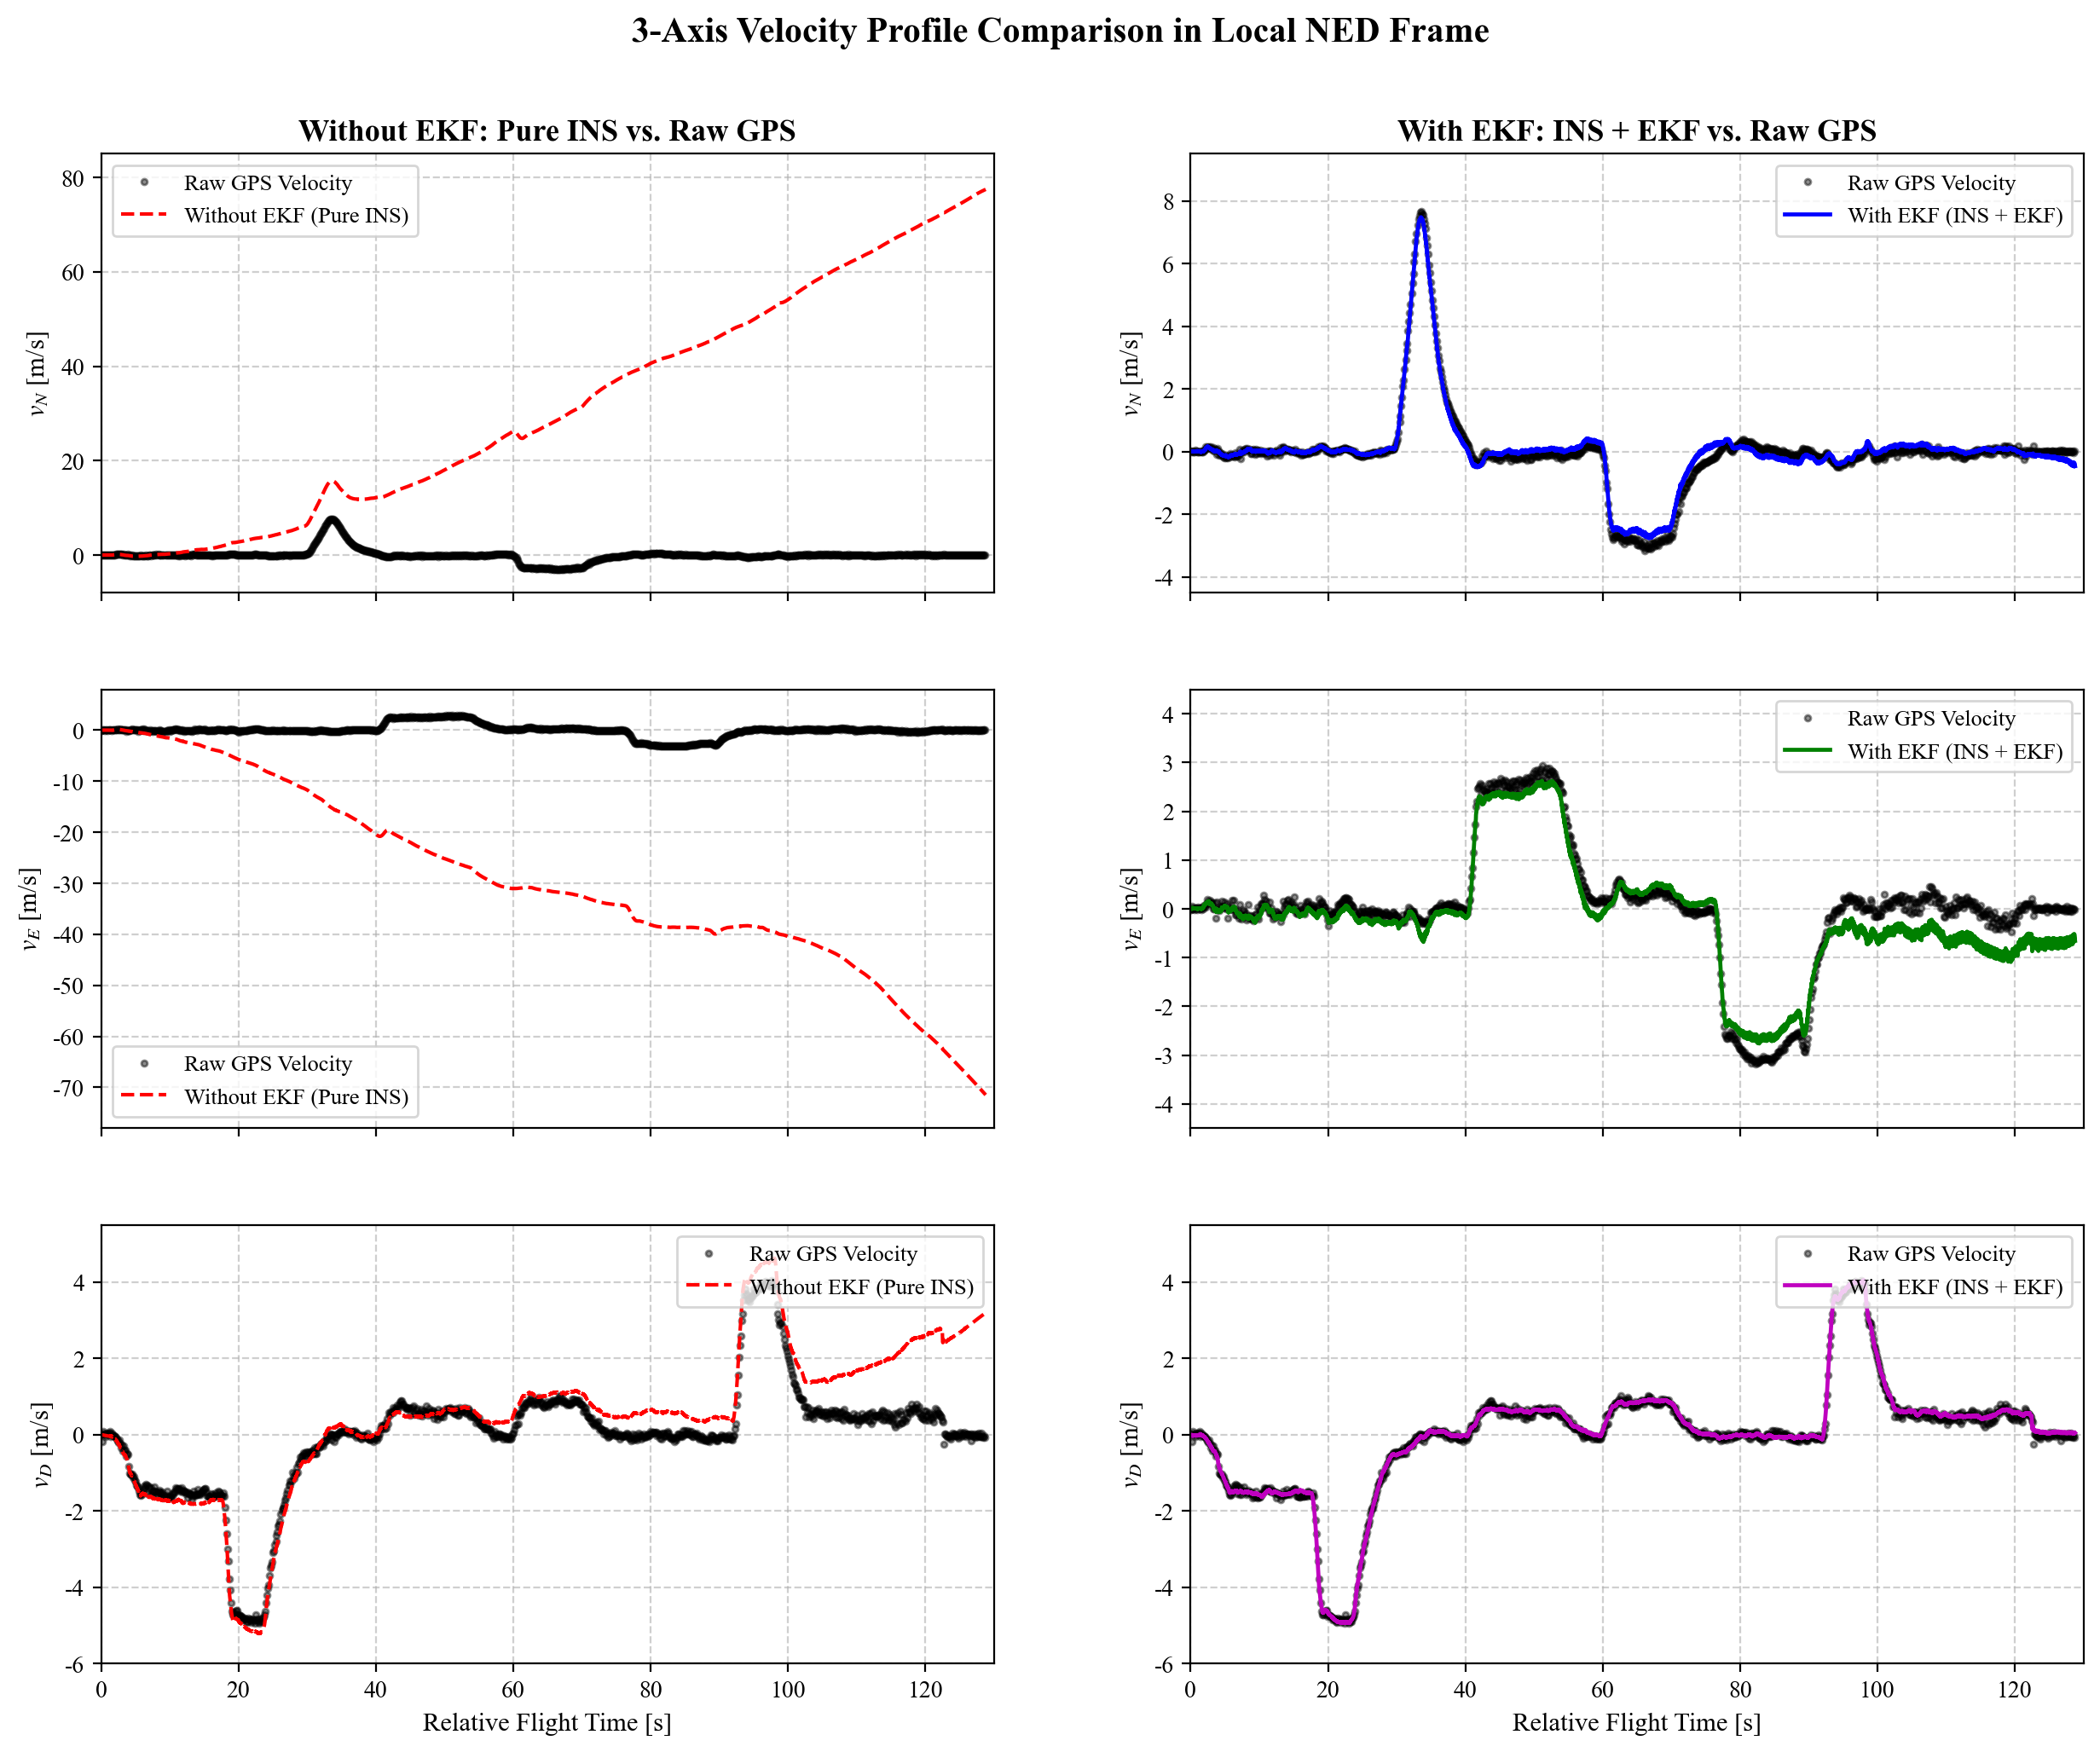

,Axis / Metric,Pure INS RMSE,Pure INS Max Error,INS+EKF MAE,INS+EKF MSE,INS+EKF RMSE,INS+EKF Max Error,RMSE Reduction (%)
0,North Velocity v_N [m/s],39.6192,77.3716,0.1467,0.0347,0.1862,0.6269,99.5300
1,East Velocity v_E [m/s],34.3184,71.2832,0.3042,0.1488,0.3858,0.9141,98.8759
2,Down Velocity v_D [m/s],0.9119,3.2447,0.0643,0.0066,0.0809,0.4660,91.1246
3,3D Total Velocity [m/s],52.4239,105.2529,0.3762,0.1901,0.4360,0.9433,99.1684


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Konfigurasi Global Font Times New Roman
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

# 2. Buat Kanvas 3x2 (Kiri: Without EKF, Kanan: With EKF) dengan Ukuran Kotak Identik
fig, axes = plt.subplots(3, 2, figsize=(15, 11.5), dpi=200, sharex=True)
plt.subplots_adjust(wspace=0.22, hspace=0.22)

# --- BARIS 1: North Velocity (v_N) ---
axes[0, 0].plot(df_gps['t_sec'], df_gps['vel_n_m_s'], 'ko', markersize=2.5, alpha=0.45, label='Raw GPS Velocity')
axes[0, 0].plot(df_ins['t_sec'], df_ins['v_N'], 'r--', linewidth=1.5, label='Without EKF (Pure INS)')
axes[0, 0].set_ylim(-8, 85)
axes[0, 0].set_ylabel(r'$v_N$ [m/s]', fontsize=11)
axes[0, 0].set_title('Without EKF: Pure INS vs. Raw GPS', fontsize=13, fontweight='bold')
axes[0, 0].grid(True, linestyle='--', alpha=0.6)
axes[0, 0].legend(loc='upper left', fontsize=9.5)

axes[0, 1].plot(df_gps['t_sec'], df_gps['vel_n_m_s'], 'ko', markersize=2.5, alpha=0.45, label='Raw GPS Velocity')
axes[0, 1].plot(df_ekf['t_sec'], df_ekf['v_N'], 'b-', linewidth=1.7, label='With EKF (INS + EKF)')
axes[0, 1].set_ylim(-4.5, 9.5)
axes[0, 1].set_ylabel(r'$v_N$ [m/s]', fontsize=11)
axes[0, 1].set_title('With EKF: INS + EKF vs. Raw GPS', fontsize=13, fontweight='bold')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)
axes[0, 1].legend(loc='upper right', fontsize=9.5)

# --- BARIS 2: East Velocity (v_E) ---
axes[1, 0].plot(df_gps['t_sec'], df_gps['vel_e_m_s'], 'ko', markersize=2.5, alpha=0.45, label='Raw GPS Velocity')
axes[1, 0].plot(df_ins['t_sec'], df_ins['v_E'], 'r--', linewidth=1.5, label='Without EKF (Pure INS)')
axes[1, 0].set_ylim(-78, 8)
axes[1, 0].set_ylabel(r'$v_E$ [m/s]', fontsize=11)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)
axes[1, 0].legend(loc='lower left', fontsize=9.5)

axes[1, 1].plot(df_gps['t_sec'], df_gps['vel_e_m_s'], 'ko', markersize=2.5, alpha=0.45, label='Raw GPS Velocity')
axes[1, 1].plot(df_ekf['t_sec'], df_ekf['v_E'], 'g-', linewidth=1.7, label='With EKF (INS + EKF)')
axes[1, 1].set_ylim(-4.5, 4.5)
axes[1, 1].set_ylabel(r'$v_E$ [m/s]', fontsize=11)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)
axes[1, 1].legend(loc='upper right', fontsize=9.5)

# --- BARIS 3: Down Velocity (v_D) ---
axes[2, 0].plot(df_gps['t_sec'], df_gps['vel_d_m_s'], 'ko', markersize=2.5, alpha=0.45, label='Raw GPS Velocity')
axes[2, 0].plot(df_ins['t_sec'], df_ins['v_D'], 'r--', linewidth=1.5, label='Without EKF (Pure INS)')
axes[2, 0].set_ylim(-6.0, 5.5)
axes[2, 0].set_xlim(0, 130)
axes[2, 0].set_ylabel(r'$v_D$ [m/s]', fontsize=11)
axes[2, 0].set_xlabel('Relative Flight Time [s]', fontsize=11)
axes[2, 0].grid(True, linestyle='--', alpha=0.6)
axes[2, 0].legend(loc='upper right', fontsize=9.5)

axes[2, 1].plot(df_gps['t_sec'], df_gps['vel_d_m_s'], 'ko', markersize=2.5, alpha=0.45, label='Raw GPS Velocity')
axes[2, 1].plot(df_ekf['t_sec'], df_ekf['v_D'], 'm-', linewidth=1.7, label='With EKF (INS + EKF)')
axes[2, 1].set_ylim(-6.0, 5.5)
axes[2, 1].set_xlim(0, 130)
axes[2, 1].set_ylabel(r'$v_D$ [m/s]', fontsize=11)
axes[2, 1].set_xlabel('Relative Flight Time [s]', fontsize=11)
axes[2, 1].grid(True, linestyle='--', alpha=0.6)
axes[2, 1].legend(loc='upper right', fontsize=9.5)

fig.suptitle('3-Axis Velocity Profile Comparison in Local NED Frame', fontsize=15, fontweight='bold', y=0.95)
plt.savefig('velocity_3axis_comparison.png', bbox_inches='tight')
plt.show()

# 3. Tabel Metrik Error Kecepatan 3-Sumbu (Ditampilkan Tepat di Bawah Grafik)
mask_valid = (df_gps['t_sec'] >= df_ekf['t_sec'].min()) & (df_gps['t_sec'] <= df_ekf['t_sec'].max())
gps_ref = df_gps[mask_valid].reset_index(drop=True)
t_ref = gps_ref['t_sec'].values

err_ins_vn = np.interp(t_ref, df_ins['t_sec'].values, df_ins['v_N'].values) - gps_ref['vel_n_m_s'].values
err_ins_ve = np.interp(t_ref, df_ins['t_sec'].values, df_ins['v_E'].values) - gps_ref['vel_e_m_s'].values
err_ins_vd = np.interp(t_ref, df_ins['t_sec'].values, df_ins['v_D'].values) - gps_ref['vel_d_m_s'].values
err_ins_3d = np.sqrt(err_ins_vn**2 + err_ins_ve**2 + err_ins_vd**2)

err_ekf_vn = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['v_N'].values) - gps_ref['vel_n_m_s'].values
err_ekf_ve = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['v_E'].values) - gps_ref['vel_e_m_s'].values
err_ekf_vd = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['v_D'].values) - gps_ref['vel_d_m_s'].values
err_ekf_3d = np.sqrt(err_ekf_vn**2 + err_ekf_ve**2 + err_ekf_vd**2)

def calc_stats(err):
    mae   = np.mean(np.abs(err))
    mse   = np.mean(err**2)
    rmse  = np.sqrt(mse)
    max_e = np.max(np.abs(err))
    return mae, mse, rmse, max_e

rows = []
for label, e_ins, e_ekf in [
    ('North Velocity v_N [m/s]', err_ins_vn, err_ekf_vn),
    ('East Velocity v_E [m/s]', err_ins_ve, err_ekf_ve),
    ('Down Velocity v_D [m/s]', err_ins_vd, err_ekf_vd),
    ('3D Total Velocity [m/s]', err_ins_3d, err_ekf_3d)
]:
    _, _, ins_rmse, ins_max = calc_stats(e_ins)
    ekf_mae, ekf_mse, ekf_rmse, ekf_max = calc_stats(e_ekf)
    rows.append({
        'Axis / Metric': label,
        'Pure INS RMSE': ins_rmse,
        'Pure INS Max Error': ins_max,
        'INS+EKF MAE': ekf_mae,
        'INS+EKF MSE': ekf_mse,
        'INS+EKF RMSE': ekf_rmse,
        'INS+EKF Max Error': ekf_max,
        'RMSE Reduction (%)': (1.0 - ekf_rmse / ins_rmse) * 100.0
    })

df_vel_table = pd.DataFrame(rows)
display(df_vel_table.round(4))

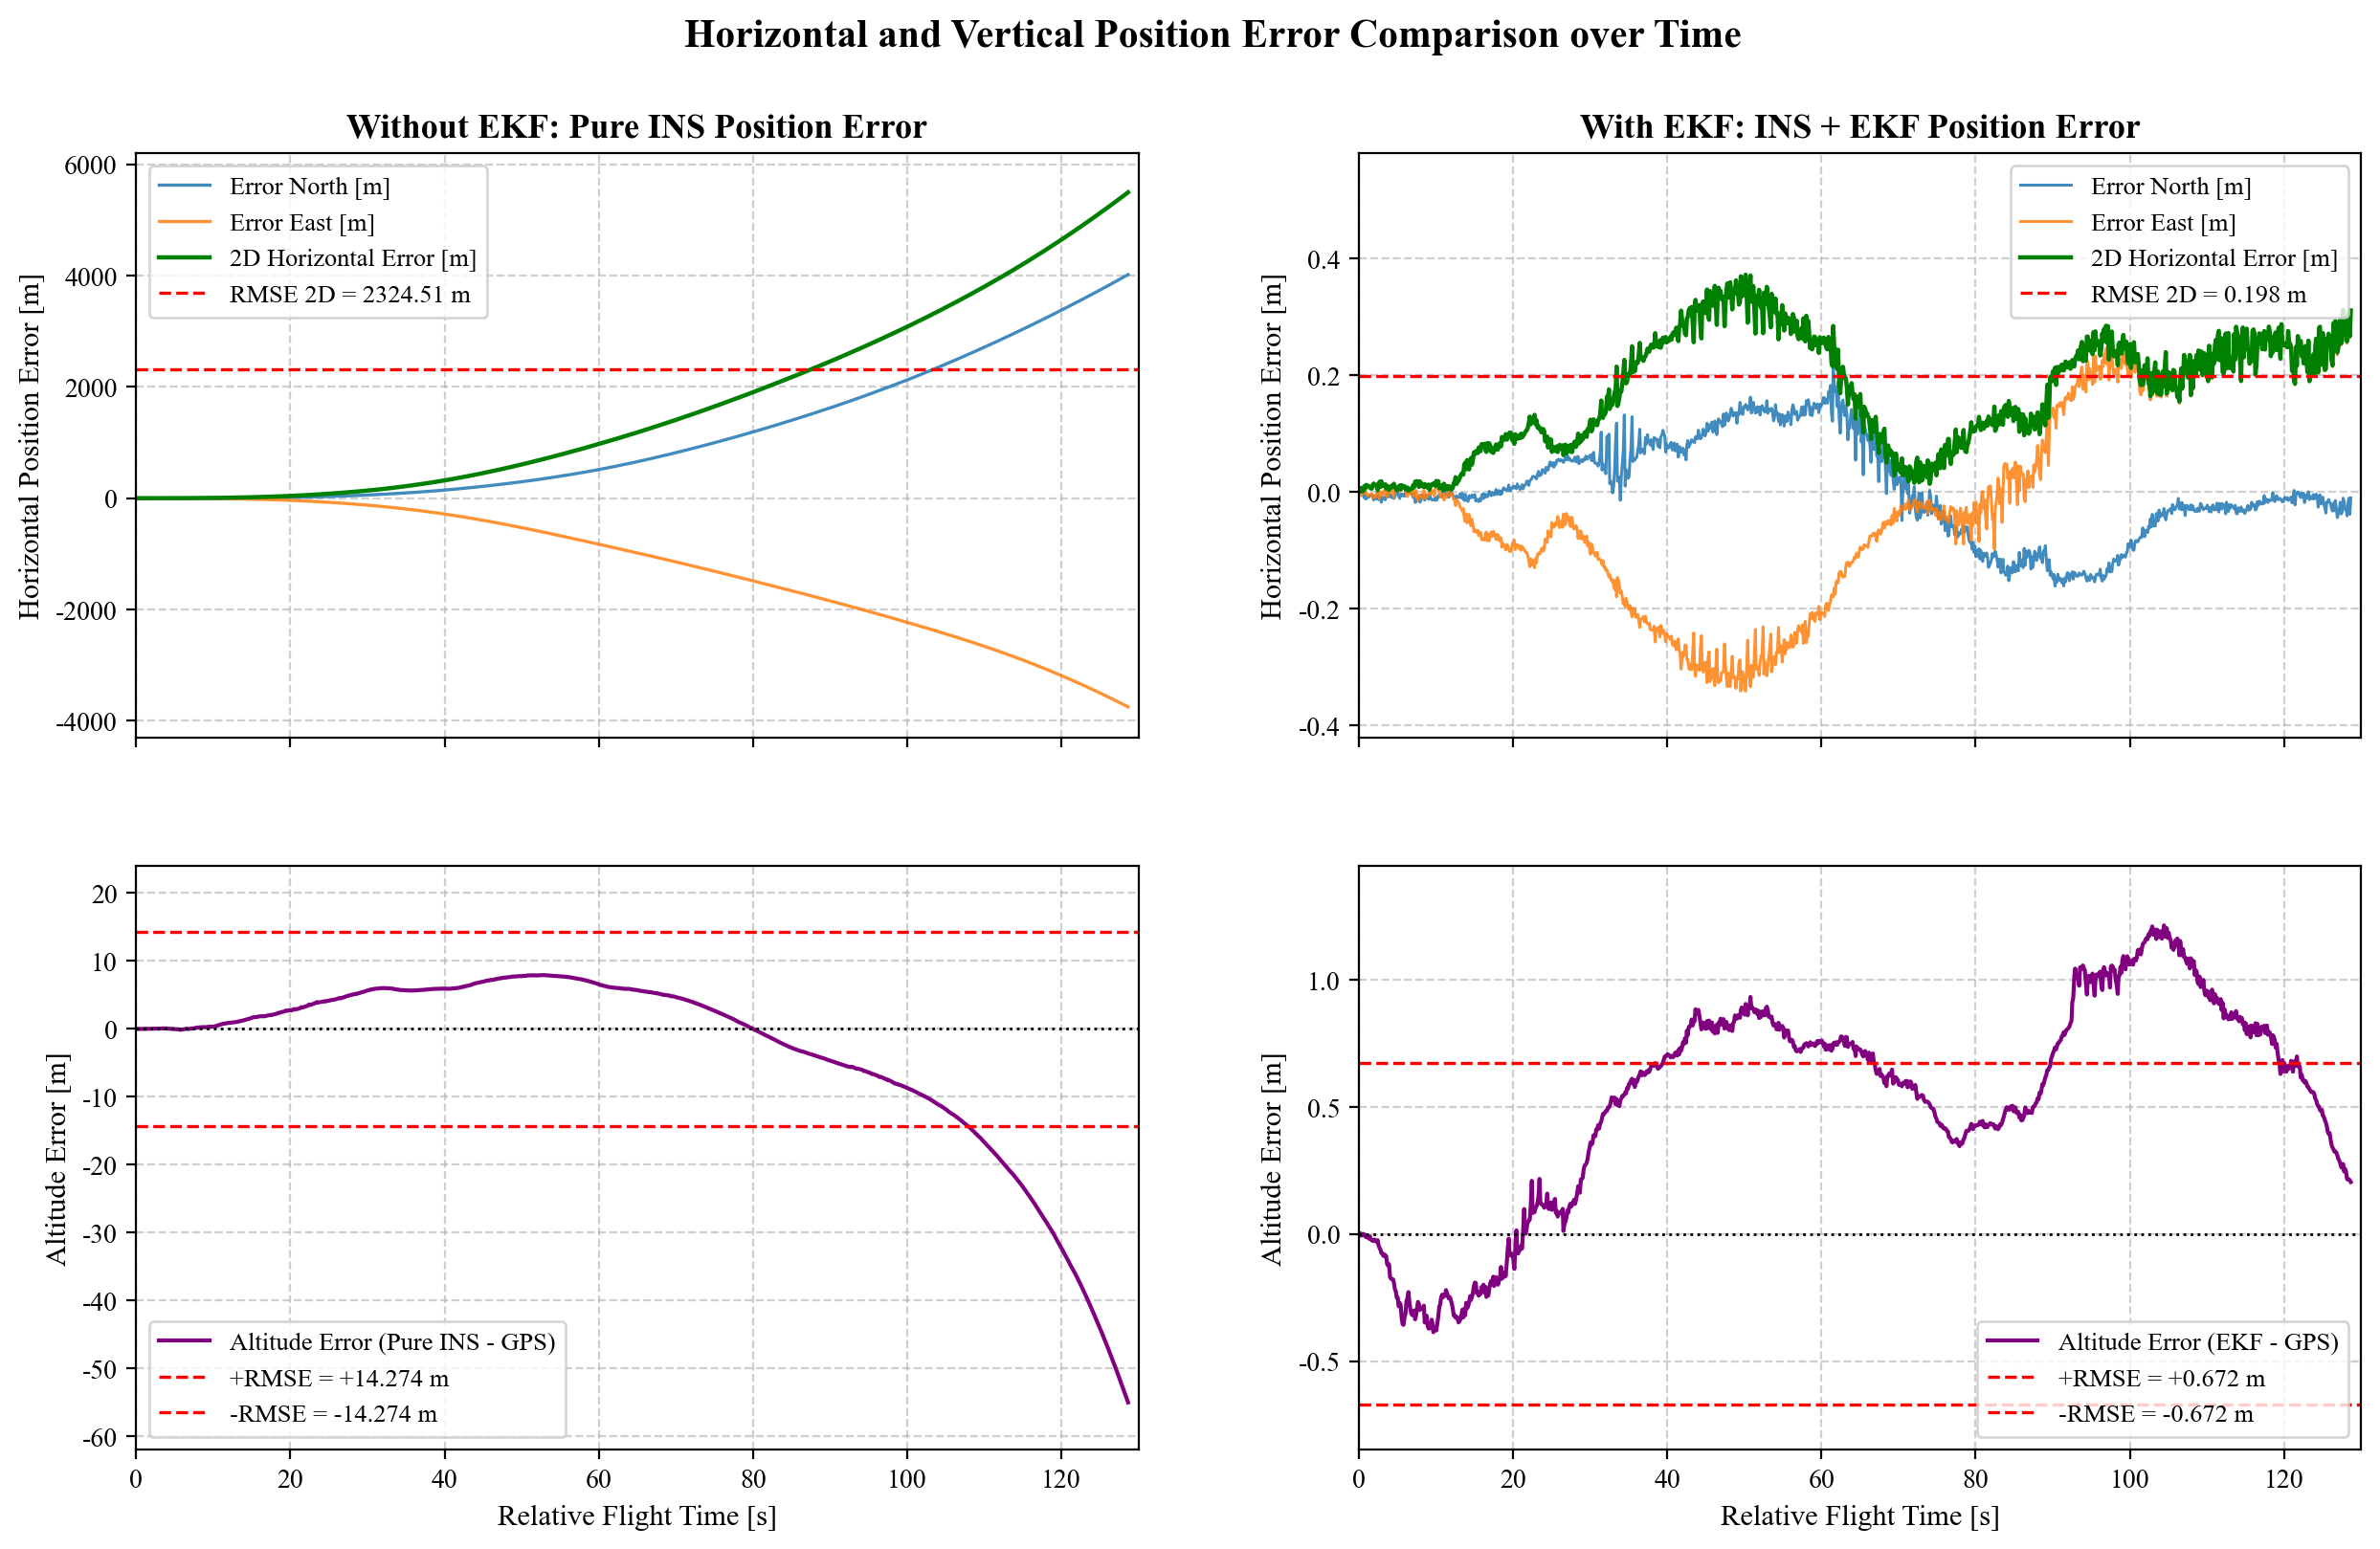

,Axis / Metric,Pure INS RMSE,Pure INS Max Error,INS+EKF MAE,INS+EKF MSE,INS+EKF RMSE,INS+EKF Max Error,RMSE Reduction (%)
0,North Position [m],1630.9753,4018.9217,0.0653,0.0070,0.0834,0.2207,99.9949
1,East Position [m],1656.2769,3752.2096,0.1489,0.0324,0.1799,0.3407,99.9891
2,2D Horizontal Position [m],2324.5072,5498.2550,0.1713,0.0393,0.1983,0.3723,99.9915
3,Ellipsoid Altitude [m],14.2745,55.0073,0.5979,0.4520,0.6723,1.2154,95.2899
4,3D Total Position [m],2324.5511,5498.5302,0.6276,0.4914,0.7010,1.2289,99.9698


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Konfigurasi Global Font Times New Roman
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

# 2. Hitung Seluruh Variabel Galat Tersinkronisasi
mask_valid = (df_gps['t_sec'] >= df_ekf['t_sec'].min()) & (df_gps['t_sec'] <= df_ekf['t_sec'].max())
gps_ref = df_gps[mask_valid].reset_index(drop=True)
t_ref = gps_ref['t_sec'].values

err_ins_n  = np.interp(t_ref, df_ins['t_sec'].values, df_ins['North_m'].values) - gps_ref['North_m'].values
err_ins_e  = np.interp(t_ref, df_ins['t_sec'].values, df_ins['East_m'].values) - gps_ref['East_m'].values
err_ins_2d = np.sqrt(err_ins_n**2 + err_ins_e**2)
err_ins_h  = np.interp(t_ref, df_ins['t_sec'].values, df_ins['height_m'].values) - gps_ref['altitude_ellipsoid_m'].values

err_ekf_n  = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['North_m'].values) - gps_ref['North_m'].values
err_ekf_e  = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['East_m'].values) - gps_ref['East_m'].values
err_ekf_2d = np.sqrt(err_ekf_n**2 + err_ekf_e**2)
err_ekf_h  = np.interp(t_ref, df_ekf['t_sec'].values, df_ekf['height_m'].values) - gps_ref['altitude_ellipsoid_m'].values

# 3. Buat Kanvas 2x2 (Kiri: Without EKF, Kanan: With EKF) dengan Ukuran Kotak Identik
fig, axes = plt.subplots(2, 2, figsize=(15, 8.8), dpi=200, sharex=True)
plt.subplots_adjust(wspace=0.22, hspace=0.22)

# --- BARIS 1: Horizontal Position Error ---
# Kiri: Without EKF (Pure INS)
rmse_ins_2d = np.sqrt(np.mean(err_ins_2d**2))
axes[0, 0].plot(t_ref, err_ins_n, linewidth=1.2, alpha=0.85, label='Error North [m]')
axes[0, 0].plot(t_ref, err_ins_e, linewidth=1.2, alpha=0.85, label='Error East [m]')
axes[0, 0].plot(t_ref, err_ins_2d, color='green', linewidth=1.6, label='2D Horizontal Error [m]')
axes[0, 0].axhline(rmse_ins_2d, color='red', linestyle='--', linewidth=1.2, label=f'RMSE 2D = {rmse_ins_2d:.2f} m')
axes[0, 0].set_ylim(-4300, 6200)
axes[0, 0].set_ylabel('Horizontal Position Error [m]', fontsize=11)
axes[0, 0].set_title('Without EKF: Pure INS Position Error', fontsize=13, fontweight='bold')
axes[0, 0].grid(True, linestyle='--', alpha=0.6)
axes[0, 0].legend(loc='upper left', fontsize=9.5)

# Kanan: With EKF (INS + EKF)
rmse_ekf_2d = np.sqrt(np.mean(err_ekf_2d**2))
axes[0, 1].plot(t_ref, err_ekf_n, linewidth=1.1, alpha=0.85, label='Error North [m]')
axes[0, 1].plot(t_ref, err_ekf_e, linewidth=1.1, alpha=0.85, label='Error East [m]')
axes[0, 1].plot(t_ref, err_ekf_2d, color='green', linewidth=1.6, label='2D Horizontal Error [m]')
axes[0, 1].axhline(rmse_ekf_2d, color='red', linestyle='--', linewidth=1.2, label=f'RMSE 2D = {rmse_ekf_2d:.3f} m')
axes[0, 1].set_ylim(-0.42, 0.58)
axes[0, 1].set_ylabel('Horizontal Position Error [m]', fontsize=11)
axes[0, 1].set_title('With EKF: INS + EKF Position Error', fontsize=13, fontweight='bold')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)
axes[0, 1].legend(loc='upper right', fontsize=9.5)

# --- BARIS 2: Vertical Altitude Error ---
# Kiri: Without EKF (Pure INS)
rmse_ins_h = np.sqrt(np.mean(err_ins_h**2))
axes[1, 0].plot(t_ref, err_ins_h, color='purple', linewidth=1.5, label='Altitude Error (Pure INS - GPS)')
axes[1, 0].axhline(0, color='black', linestyle=':', linewidth=1.0)
axes[1, 0].axhline(rmse_ins_h, color='red', linestyle='--', linewidth=1.2, label=f'+RMSE = +{rmse_ins_h:.3f} m')
axes[1, 0].axhline(-rmse_ins_h, color='red', linestyle='--', linewidth=1.2, label=f'-RMSE = -{rmse_ins_h:.3f} m')
axes[1, 0].set_ylim(-62, 24)
axes[1, 0].set_xlim(0, 130)
axes[1, 0].set_ylabel('Altitude Error [m]', fontsize=11)
axes[1, 0].set_xlabel('Relative Flight Time [s]', fontsize=11)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)
axes[1, 0].legend(loc='lower left', fontsize=9.5)

# Kanan: With EKF (INS + EKF)
rmse_ekf_h = np.sqrt(np.mean(err_ekf_h**2))
axes[1, 1].plot(t_ref, err_ekf_h, color='purple', linewidth=1.5, label='Altitude Error (EKF - GPS)')
axes[1, 1].axhline(0, color='black', linestyle=':', linewidth=1.0)
axes[1, 1].axhline(rmse_ekf_h, color='red', linestyle='--', linewidth=1.2, label=f'+RMSE = +{rmse_ekf_h:.3f} m')
axes[1, 1].axhline(-rmse_ekf_h, color='red', linestyle='--', linewidth=1.2, label=f'-RMSE = -{rmse_ekf_h:.3f} m')
axes[1, 1].set_ylim(-0.85, 1.45)
axes[1, 1].set_xlim(0, 130)
axes[1, 1].set_ylabel('Altitude Error [m]', fontsize=11)
axes[1, 1].set_xlabel('Relative Flight Time [s]', fontsize=11)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)
axes[1, 1].legend(loc='lower right', fontsize=9.5)

fig.suptitle('Horizontal and Vertical Position Error Comparison over Time', fontsize=15, fontweight='bold', y=0.96)
plt.savefig('position_error_comparison.png', bbox_inches='tight')
plt.show()

# 4. Tabel Metrik Galat Posisi Horizontal & Vertikal
def calc_stats(err):
    mae   = np.mean(np.abs(err))
    mse   = np.mean(err**2)
    rmse  = np.sqrt(mse)
    max_e = np.max(np.abs(err))
    return mae, mse, rmse, max_e

err_ins_3d = np.sqrt(err_ins_n**2 + err_ins_e**2 + err_ins_h**2)
err_ekf_3d = np.sqrt(err_ekf_n**2 + err_ekf_e**2 + err_ekf_h**2)

rows = []
for label, e_ins, e_ekf in [
    ('North Position [m]', err_ins_n, err_ekf_n),
    ('East Position [m]', err_ins_e, err_ekf_e),
    ('2D Horizontal Position [m]', err_ins_2d, err_ekf_2d),
    ('Ellipsoid Altitude [m]', err_ins_h, err_ekf_h),
    ('3D Total Position [m]', err_ins_3d, err_ekf_3d)
]:
    _, _, ins_rmse, ins_max = calc_stats(e_ins)
    ekf_mae, ekf_mse, ekf_rmse, ekf_max = calc_stats(e_ekf)
    rows.append({
        'Axis / Metric': label,
        'Pure INS RMSE': ins_rmse,
        'Pure INS Max Error': ins_max,
        'INS+EKF MAE': ekf_mae,
        'INS+EKF MSE': ekf_mse,
        'INS+EKF RMSE': ekf_rmse,
        'INS+EKF Max Error': ekf_max,
        'RMSE Reduction (%)': (1.0 - ekf_rmse / ins_rmse) * 100.0
    })

df_pos_err_table = pd.DataFrame(rows)
display(df_pos_err_table.round(4))

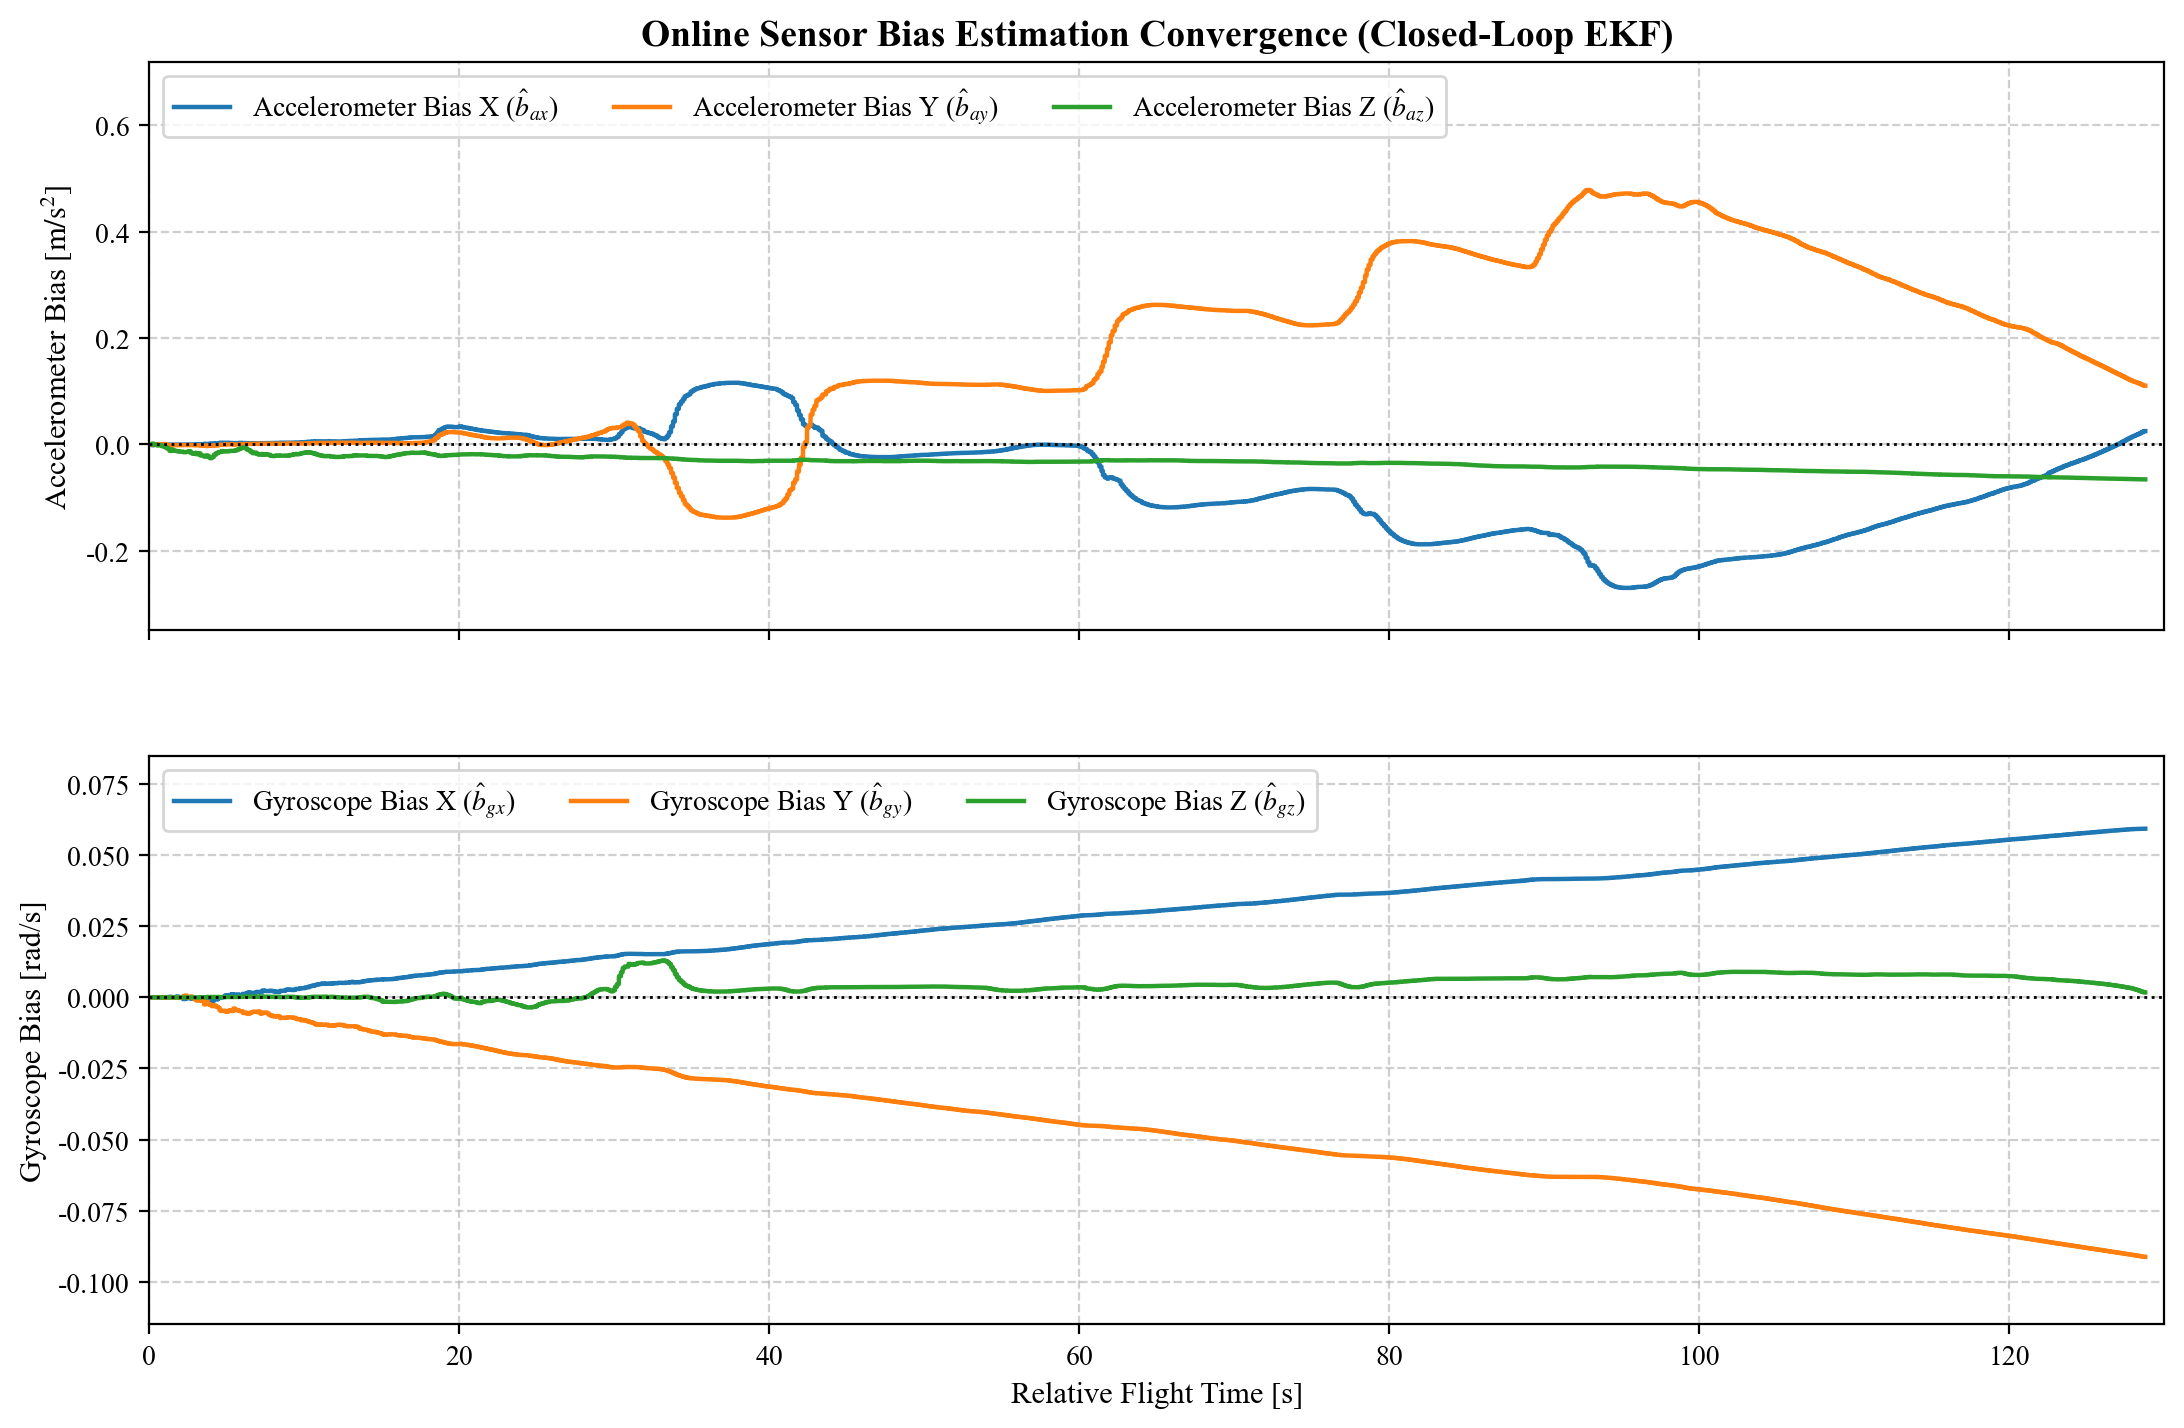

,Sensor Bias State,Initial Value,Final Value (t=128.8s),Mean,Std Dev,Min,Max
0,Accelerometer Bias X [m/s²],0.0,0.025020,-0.066164,0.096799,-0.270102,0.116018
1,Accelerometer Bias Y [m/s²],0.0,0.110312,0.174441,0.169899,-0.137976,0.478651
2,Accelerometer Bias Z [m/s²],0.0,-0.065775,-0.035233,0.013614,-0.065775,0.001464
3,Gyroscope Bias X [rad/s],0.0,0.059304,0.029606,0.017231,-0.001968,0.059304
4,Gyroscope Bias Y [rad/s],0.0,-0.091236,-0.046166,0.024955,-0.091236,0.000624
5,Gyroscope Bias Z [rad/s],0.0,0.001727,0.004244,0.003320,-0.003547,0.012994


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Konfigurasi Global Font Times New Roman
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

# 2. Buat Kanvas 2x1 dengan Ukuran Bingkai Identik
fig, axes = plt.subplots(2, 1, figsize=(13, 8.2), dpi=200, sharex=True)
plt.subplots_adjust(hspace=0.22)

# --- GRAFIK ATAS: Estimasi Bias Akselerometer ---
axes[0].plot(df_ekf['t_sec'], df_ekf['bias_ax'], linewidth=1.6, label=r'Accelerometer Bias X ($\hat{b}_{ax}$)')
axes[0].plot(df_ekf['t_sec'], df_ekf['bias_ay'], linewidth=1.6, label=r'Accelerometer Bias Y ($\hat{b}_{ay}$)')
axes[0].plot(df_ekf['t_sec'], df_ekf['bias_az'], linewidth=1.6, label=r'Accelerometer Bias Z ($\hat{b}_{az}$)')
axes[0].axhline(0, color='black', linestyle=':', linewidth=1.0)
axes[0].set_ylim(-0.35, 0.72)
axes[0].set_ylabel(r'Accelerometer Bias [$\mathrm{m/s^2}$]', fontsize=11)
axes[0].set_title('Online Sensor Bias Estimation Convergence (Closed-Loop EKF)', fontsize=13.5, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='upper left', fontsize=10, ncol=3)

# --- GRAFIK BAWAH: Estimasi Bias Giroskop ---
axes[1].plot(df_ekf['t_sec'], df_ekf['bias_gx'], linewidth=1.6, label=r'Gyroscope Bias X ($\hat{b}_{gx}$)')
axes[1].plot(df_ekf['t_sec'], df_ekf['bias_gy'], linewidth=1.6, label=r'Gyroscope Bias Y ($\hat{b}_{gy}$)')
axes[1].plot(df_ekf['t_sec'], df_ekf['bias_gz'], linewidth=1.6, label=r'Gyroscope Bias Z ($\hat{b}_{gz}$)')
axes[1].axhline(0, color='black', linestyle=':', linewidth=1.0)
axes[1].set_xlim(0, 130)
axes[1].set_ylim(-0.115, 0.085)
axes[1].set_ylabel('Gyroscope Bias [rad/s]', fontsize=11)
axes[1].set_xlabel('Relative Flight Time [s]', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='upper left', fontsize=10, ncol=3)

plt.savefig('sensor_bias_convergence_en.png', bbox_inches='tight')
plt.show()

# 3. Tabel Ringkasan Statistik Estimasi Bias Sensor (Ditampilkan Tepat di Bawah Grafik)
bias_specs = [
    ('Accelerometer Bias X [m/s²]', 'bias_ax'),
    ('Accelerometer Bias Y [m/s²]', 'bias_ay'),
    ('Accelerometer Bias Z [m/s²]', 'bias_az'),
    ('Gyroscope Bias X [rad/s]',    'bias_gx'),
    ('Gyroscope Bias Y [rad/s]',    'bias_gy'),
    ('Gyroscope Bias Z [rad/s]',    'bias_gz'),
]

rows = []
for label, col in bias_specs:
    s = df_ekf[col]
    rows.append({
        'Sensor Bias State': label,
        'Initial Value': s.iloc[0],
        'Final Value (t=128.8s)': s.iloc[-1],
        'Mean': s.mean(),
        'Std Dev': s.std(),
        'Min': s.min(),
        'Max': s.max()
    })

df_bias_table = pd.DataFrame(rows)
display(df_bias_table.round(6))